# Operationalizing Verification and Validation for Text Corpora
## A Parameter-Free Information-Theoretic Framework
#### By:  Emmanuel Okoaze, W. J. Teahan (PhD.)

This single notebook reproduces the **entire experiment**: the metric, the novel
smoothing, corpus acquisition, defect injection, the six-corpus experiment,
document-level detection, the analysis, and every figure.

It follows the same logical chain as the paper:

> **Problem** → **Evidence-location principle** → **Defect → measurement level** →
> **RGT** (corpus-level instrument) → **Controlled injection** (ground truth) →
> **Experiment** → **Results support the framework**

All randomness is seeded; results are deterministic.

**Runtime:** ~15–20 min for the full corpus-level sweep on a 16gb RAM laptop.
**Data note:** four corpora are fetched automatically; the two AfriBERTa corpora
(Igbo, Nigerian Pidgin) are placed manually — see *Step 5* below.

In [1]:
# Dependencies
import sys, subprocess
for pkg in ["numpy", "scipy", "regex", "matplotlib"]:
    try: __import__(pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", pkg, "-q"])
print("environment ready")

environment ready


---
## Step 1 · The problem

Empirical NLP rests on corpora, yet the corpus is rarely subjected to the
verification & validation (V&V) that engineering demands of any other component.
A manual audit of 205 multilingual corpora was found to have many with no usable text and
hundreds mislabelled. This experiment aims to give corpus V&V a **measurable** basis.

---
## Step 2 · The evidence-location principle

Different defects leave their evidence in different places:

| Defect kind | Evidence lives in | Instrument |
|---|---|---|
| **Structural** (duplication, truncation, boilerplate) | relations *between* documents | document-level |
| **Content** (foreign text, encoding corruption) | the *aggregate* distribution | corpus-level |

This is the organising principle. Everything below tests the prediction that
falls out of it: *each defect is caught by the instrument that looks where its
evidence lives, and missed by the other.*

---
## Step 3–4 · The measure and the parameter-free instrument (RGT)

Comparing two corpora by information divergence needs a probability for every
n-gram over the **union** of their vocabularies, including n-grams seen in only
one corpus. We use **Jensen–Shannon divergence** (symmetric, bounded), and to
estimate the probabilities we introduce **Reciprocal Good–Turing (RGT)**
smoothing: reserve the Good–Turing singleton mass and redistribute it toward the
comparison partner, not uniformly. No free parameter.

### 4.1 Tokenizer, n-grams, JSD, and the add-k / frequency baselines

In [2]:
from __future__ import annotations
from collections import Counter
from typing import Iterable, Sequence
import math
import regex as _re

# A token is a letter/digit followed by any letters, digits, or combining marks.
# \p{M} is essential for vocalized Arabic: diacritics are Unicode category Mn, 
# which \w does NOT match, so a naive \w+ pattern silently shatters each vocalized word into single letters.
_WORD_RE = _re.compile(r"[\p{L}\p{N}][\p{L}\p{N}\p{M}]*", _re.UNICODE)


def tokenize(text: str) -> list[str]:
    """Lowercase word tokenization, Unicode-aware (Latin, Arabic...)."""
    return _WORD_RE.findall(text.lower())


def ngrams(tokens: Sequence[str], n: int) -> list[tuple[str, ...]]:
    if n <= 0:
        raise ValueError("n must be >= 1")
    if len(tokens) < n:
        return []
    return [tuple(tokens[i:i + n]) for i in range(len(tokens) - n + 1)]


def ngram_counts(tokens: Sequence[str], n: int) -> Counter:
    return Counter(ngrams(tokens, n))


def _smoothed_probs(counts: Counter, vocab: set, N: int, k: float):
    """add-k smoothed probability over the FULL vocab union."""
    V = len(vocab)
    denom = N + k * V
    # every g in vocab gets nonzero mass; g absent from this text -> count 0
    return {g: (counts.get(g, 0) + k) / denom for g in vocab}


def jensen_shannon(counts1: Counter, counts2: Counter, k: float = 0.1) -> float:
    """
    Jensen-Shannon divergence in bits between two n-gram count distributions.
    0 <= JSD <= 1. 0 iff identical distributions.
    """
    vocab = set(counts1) | set(counts2)
    if not vocab:
        return 0.0
    N1 = sum(counts1.values())
    N2 = sum(counts2.values())
    P = _smoothed_probs(counts1, vocab, N1, k)
    Q = _smoothed_probs(counts2, vocab, N2, k)
    jsd = 0.0
    for g in vocab:
        p, q = P[g], Q[g]
        m = 0.5 * (p + q)
        if p > 0:
            jsd += 0.5 * p * math.log2(p / m)
        if q > 0:
            jsd += 0.5 * q * math.log2(q / m)
    # numerical floor
    return max(0.0, jsd)


def js_distance(counts1: Counter, counts2: Counter, k: float = 0.1) -> float:
    """sqrt(JSD): a true metric (satisfies triangle inequality)."""
    return math.sqrt(jensen_shannon(counts1, counts2, k))


def pointwise_contributions(counts1: Counter, counts2: Counter, k: float = 0.1):
    """
    Per-n-gram contribution to JSD (>=0, sums to JSD). For ranking the n-grams
    that drive the divergence — the corrected replacement for |log-ratio| ranking.
    Returns list of (ngram, contribution) sorted descending.
    """
    vocab = set(counts1) | set(counts2)
    N1 = sum(counts1.values())
    N2 = sum(counts2.values())
    P = _smoothed_probs(counts1, vocab, N1, k)
    Q = _smoothed_probs(counts2, vocab, N2, k)
    out = []
    for g in vocab:
        p, q = P[g], Q[g]
        m = 0.5 * (p + q)
        c = 0.0
        if p > 0:
            c += 0.5 * p * math.log2(p / m)
        if q > 0:
            c += 0.5 * q * math.log2(q / m)
        out.append((g, c))
    out.sort(key=lambda x: x[1], reverse=True)
    return out


def jensen_shannon_fast(counts1: Counter, counts2: Counter, k: float = 0.1) -> float:
    """Vectorized JSD (numpy) — identical result to jensen_shannon, much faster."""
    import numpy as np
    vocab = set(counts1) | set(counts2)
    if not vocab:
        return 0.0
    vocab = list(vocab)
    N1 = sum(counts1.values()); N2 = sum(counts2.values())
    V = len(vocab)
    c1 = np.fromiter((counts1.get(g, 0) for g in vocab), dtype=np.float64, count=V)
    c2 = np.fromiter((counts2.get(g, 0) for g in vocab), dtype=np.float64, count=V)
    p = (c1 + k) / (N1 + k * V)
    q = (c2 + k) / (N2 + k * V)
    m = 0.5 * (p + q)
    jsd = 0.5 * np.sum(p * np.log2(p / m)) + 0.5 * np.sum(q * np.log2(q / m))
    return float(max(0.0, jsd))


def token_freq_baseline(counts1: Counter, counts2: Counter) -> float:
    """
    Baseline: mean absolute difference of relative frequencies over the shared vocabulary 
    union (L1 / total variation style). Intentionally simple and unweighted-by-information.
    """
    vocab = set(counts1) | set(counts2)
    if not vocab:
        return 0.0
    N1 = sum(counts1.values()) or 1
    N2 = sum(counts2.values()) or 1
    return sum(abs(counts1.get(g, 0) / N1 - counts2.get(g, 0) / N2)
               for g in vocab) / len(vocab)


def evaluate_pair(text1: str, text2: str, n: int = 1, k: float = 0.1) -> dict:
    """Convenience: full comparison of two raw texts at n-gram order n."""
    t1, t2 = tokenize(text1), tokenize(text2)
    c1, c2 = ngram_counts(t1, n), ngram_counts(t2, n)
    return {
        "n": n,
        "jsd_bits": jensen_shannon(c1, c2, k),
        "js_distance": js_distance(c1, c2, k),
        "baseline_l1": token_freq_baseline(c1, c2),
        "tokens_1": len(t1),
        "tokens_2": len(t2),
        "types_1": len(c1),
        "types_2": len(c2),
    }

### 4.2 Reciprocal Good–Turing smoothing (the estimator)

In [3]:
from __future__ import annotations
from collections import Counter
import numpy as np

THETA_CAP = 0.5


def gt_theta(counts: Counter, N: int) -> float:
    """Good-Turing estimate of unseen mass: n_1 / N (fraction of singleton types)."""
    if N <= 0:
        return 0.0
    n1 = sum(1 for c in counts.values() if c == 1)
    return n1 / N


def rgt_distributions(counts1: Counter, counts2: Counter):
    """
    Return (vocab, P, Q) as numpy arrays over the vocabulary union, each smoothed
    toward the other by Reciprocal Good-Turing. Both sum to 1.
    """
    vocab = list(set(counts1) | set(counts2))
    V = len(vocab)
    if V == 0:
        return vocab, np.array([]), np.array([])

    N1 = sum(counts1.values())
    N2 = sum(counts2.values())
    c1 = np.fromiter((counts1.get(g, 0) for g in vocab), dtype=np.float64, count=V)
    c2 = np.fromiter((counts2.get(g, 0) for g in vocab), dtype=np.float64, count=V)

    raw1 = c1 / N1 if N1 else np.zeros(V)
    raw2 = c2 / N2 if N2 else np.zeros(V)

    unseen1 = c1 == 0          # in the union but absent from corpus 1
    unseen2 = c2 == 0

    def build(raw_self, raw_partner, unseen_self, counts_self, N_self):
        P = np.empty(V)
        if not unseen_self.any():
            return raw_self.copy()           # nothing to reserve for
        theta = gt_theta(counts_self, N_self)
        theta = max(theta, 1.0 / (N_self + 1.0))   # floor: keep strictly positive
        theta = min(theta, THETA_CAP)              # cap: seen keeps majority mass
        partner_mass = raw_partner[unseen_self].sum()
        P[~unseen_self] = (1.0 - theta) * raw_self[~unseen_self]
        if partner_mass > 0:
            P[unseen_self] = theta * raw_partner[unseen_self] / partner_mass
        else:
            P[unseen_self] = theta / unseen_self.sum()
        return P

    P = build(raw1, raw2, unseen1, counts1, N1)
    Q = build(raw2, raw1, unseen2, counts2, N2)
    return vocab, P, Q


def _jsd_from_pq(P, Q):
    if P.size == 0:
        return 0.0
    M = 0.5 * (P + Q)
    ok = M > 0
    t1 = np.where((P > 0) & ok, P * np.log2(np.divide(P, M, out=np.ones_like(P), where=ok)), 0.0)
    t2 = np.where((Q > 0) & ok, Q * np.log2(np.divide(Q, M, out=np.ones_like(Q), where=ok)), 0.0)
    return float(max(0.0, 0.5 * t1.sum() + 0.5 * t2.sum()))


def jsd_rgt(counts1: Counter, counts2: Counter) -> float:
    """Jensen-Shannon divergence (bits) under RGT smoothing. No free parameter."""
    _, P, Q = rgt_distributions(counts1, counts2)
    return _jsd_from_pq(P, Q)


def js_distance_rgt(counts1: Counter, counts2: Counter) -> float:
    return jsd_rgt(counts1, counts2) ** 0.5


def pointwise_rgt(counts1: Counter, counts2: Counter):
    """Per-n-gram contribution to JSD (>=0, sums to JSD), sorted descending."""
    vocab, P, Q = rgt_distributions(counts1, counts2)
    M = 0.5 * (P + Q)
    ok = M > 0
    t1 = np.where((P > 0) & ok, P * np.log2(np.divide(P, M, out=np.ones_like(P), where=ok)), 0.0)
    t2 = np.where((Q > 0) & ok, Q * np.log2(np.divide(Q, M, out=np.ones_like(Q), where=ok)), 0.0)
    contrib = 0.5 * t1 + 0.5 * t2
    order = np.argsort(-contrib)
    return [(vocab[i], float(contrib[i])) for i in order]


def theta_report(counts: Counter) -> dict:
    """Diagnostic: the data-derived smoothing strength for a corpus."""
    N = sum(counts.values())
    n1 = sum(1 for c in counts.values() if c == 1)
    return {"tokens": N, "types": len(counts), "singletons": n1,
            "theta": gt_theta(counts, N)}

**Quick property check**: RGT is symmetric, bounded in [0,1], zero on identical
inputs, and θ is derived from the data (no parameter):

In [4]:
from collections import Counter
a = Counter({"the":100,"cat":10,"sat":5,"mat":1})
b = Counter({"the":100,"dog":10,"ran":5,"far":1})
print("theta(A)      =", round(gt_theta(a, sum(a.values())), 5), "(data-derived, no parameter)")
print("JSD(A,A)      =", round(jsd_rgt(a,a), 10), "(identity)")
print("JSD(A,B)      =", round(jsd_rgt(a,b), 5))
print("symmetric     =", abs(jsd_rgt(a,b)-jsd_rgt(b,a)) < 1e-12)

theta(A)      = 0.00862 (data-derived, no parameter)
JSD(A,A)      = 0.0 (identity)
JSD(A,B)      = 0.09817
symmetric     = True


---
## Step 5 · Controlled injection supplies ground truth

To *test* whether an instrument detects a defect we need the correct answer.
We manufacture it: take a clean corpus, split it into a trusted **reference**
half and a **test** half, then inject a **known** defect at a **known** rate into
the test half. Because we created the defect, detection becomes falsifiable.

### 5.1 Corpus acquisition

Four corpora are fetched from public sources. The two AfriBERTa corpora
(Igbo, Pidgin) are BBC-News-derived; obtained them from the AfriBERTa dataset and
placed in `corpora/igbo.txt` and `corpora/pidgin.txt` (trim to ~2.5M chars,
drop lines < 20 chars).

In [ ]:
#!/usr/bin/env python3
"""
Corpus acquisition for the six-corpus V&V experiment.

The four Gutenberg-derived corpora (english, bible, spanish) and the Qur'an (arabic) are fetched from their
public sources here. The two AfriBERTa corpora (igbo, pidgin) are BBC-News-derived
obtained from the AfriBERTa dataset directly (see PROVENANCE below);

After running this and providing the two AfriBERTa files, corpora/ will contain:
  english.txt bible.txt spanish.txt arabic.txt igbo.txt pidgin.txt

PROVENANCE
----------
english : concatenation of six public-domain novels (Project Gutenberg):
          Pride and Prejudice (1342), The Adventures of Sherlock Holmes (1661),
          A Tale of Two Cities (98), Moby-Dick (2701), Great Expectations (1400),
          Dubliners (2814). Gutenberg licence boilerplate stripped.
bible   : King James Version (Project Gutenberg 10).
spanish : Don Quijote (Project Gutenberg 2000), Latin-1 source.
arabic  : Qur'an text (risan/quran-json), verse text concatenated.
igbo    : AfriBERTa corpus, Igbo split (Ogueji et al., 2021), ~2.5M chars.
pidgin  : AfriBERTa corpus, Nigerian Pidgin split, ~2.5M chars.

AfriBERTa: https://huggingface.co/datasets/castorini/afriberta-corpus
           (igbo/train.txt and pidgin/train.txt; trim to ~2.5M chars, drop
            lines shorter than 20 chars, as documented in the paper.)

All corpora exist in the files corpora/ folder (if missing, a rerun of this script will fetch the public ones, 
but the AfriBERTa files must be obtained separately and placed as corpora/igbo.txt and corpora/pidgin.txt).

All corpora are trimmed/normalized to be comparable in scale; see the paper's
Corpus Substrate section for the exact token/type counts used.
"""
import urllib.request, re, os, json

GUTENBERG = {
    "pride":    "https://raw.githubusercontent.com/GITenberg/Pride-and-Prejudice_1342/master/1342.txt",
    "sherlock": "https://raw.githubusercontent.com/GITenberg/The-Adventures-of-Sherlock-Holmes_1661/master/1661.txt",
    "tale":     "https://raw.githubusercontent.com/GITenberg/A-Tale-of-Two-Cities_98/master/98.txt",
    "moby":     "https://raw.githubusercontent.com/GITenberg/Moby-Dick--or-The-Whale_2701/master/2701.txt",
    "great":    "https://raw.githubusercontent.com/GITenberg/Great-Expectations_1400/master/1400.txt",
    "dubliners":"https://raw.githubusercontent.com/GITenberg/Dubliners_2814/master/2814.txt",
    "bible":    "https://raw.githubusercontent.com/GITenberg/The-King-James-Version-of-the-Bible_10/master/10.txt",
}
SPANISH = "https://raw.githubusercontent.com/GITenberg/Don-Quijote_2000/master/2000-8.txt"
QURAN   = "https://raw.githubusercontent.com/risan/quran-json/main/dist/quran.json"


def strip_gutenberg(text):
    for m in ["*** START OF THIS PROJECT GUTENBERG", "*** START OF THE PROJECT GUTENBERG",
              "***START OF THE PROJECT GUTENBERG"]:
        i = text.find(m)
        if i != -1:
            j = text.find("\n", i); text = text[j+1:] if j != -1 else text[i:]; break
    for m in ["*** END OF THIS PROJECT GUTENBERG", "*** END OF THE PROJECT GUTENBERG",
              "***END OF THE PROJECT GUTENBERG", "End of the Project Gutenberg"]:
        i = text.find(m)
        if i != -1:
            text = text[:i]; break
    text = re.sub(r"\r\n?", "\n", text)
    text = re.sub(r"\n{3,}", "\n\n", text)
    head, tail = text[:1500], text[1500:]
    head = re.sub(r"[^\n]*Project Gutenberg[^\n]*\n", "", head, flags=re.IGNORECASE)
    return (head + tail).strip()


def fetch(url, latin1=False):
    raw = urllib.request.urlopen(url, timeout=60).read()
    return raw.decode("latin-1" if latin1 else "utf-8", "replace")


def main():
    os.makedirs("corpora", exist_ok=True)

    # English: concatenate six novels
    novels = ["pride", "sherlock", "tale", "moby", "great", "dubliners"]
    parts = [strip_gutenberg(fetch(GUTENBERG[n])) for n in novels]
    open("corpora/english.txt", "w", encoding="utf-8").write("\n\n".join(parts))
    print("english.txt written")

    open("corpora/bible.txt", "w", encoding="utf-8").write(strip_gutenberg(fetch(GUTENBERG["bible"])))
    print("bible.txt written")

    sp = strip_gutenberg(fetch(SPANISH, latin1=True))
    open("corpora/spanish.txt", "w", encoding="utf-8").write(sp)
    print("spanish.txt written")

    d = json.loads(fetch(QURAN))
    ar = "\n".join(v["text"] for s in d for v in s["verses"])
    open("corpora/arabic.txt", "w", encoding="utf-8").write(ar)
    print("arabic.txt written")

    missing = [f for f in ("igbo.txt", "pidgin.txt") if not os.path.exists(f"corpora/{f}")]
    if missing:
        print("\nACTION REQUIRED: obtain the AfriBERTa files and place as:")
        for f in missing:
            print(f"  corpora/{f}")
        print("See the PROVENANCE note at the top of this file.")
    else:
        print("igbo.txt and pidgin.txt already present.")

In [8]:
import os
os.makedirs("corpora", exist_ok=True)
have = {f[:-4] for f in os.listdir("corpora") if f.endswith(".txt")}
need = {"english","bible","spanish","arabic","igbo","pidgin"}
if not (need - {"igbo","pidgin"}).issubset(have):
    main()  # fetch the four public corpora
missing = need - {f[:-4] for f in os.listdir("corpora") if f.endswith(".txt")}
print("present:", sorted(need - missing))
if missing:
    print("STILL NEEDED (place manually):", sorted(missing))

present: ['arabic', 'bible', 'english', 'igbo', 'pidgin', 'spanish']


### 5.2 Defect-injection harness and document segmentation

Five defect classes, drawn from the classes reported in real corpus audits.

In [10]:
from __future__ import annotations
import random
import re
from typing import Callable


def _pick_indices(n: int, rate: float, rng: random.Random) -> set:
    k = round(n * rate)
    if k <= 0:
        return set()
    return set(rng.sample(range(n), min(k, n)))


def inject_duplicate(docs, rate, rng, **kw):
    """Replace `rate` fraction of docs with exact copies of randomly chosen other docs."""
    docs = list(docs)
    idx = _pick_indices(len(docs), rate, rng)
    for i in idx:
        src = rng.randrange(len(docs))
        docs[i] = docs[src]
    return docs


def inject_foreign(docs, rate, rng, foreign_pool=None, **kw):
    """Replace `rate` fraction of docs with foreign-language documents."""
    if not foreign_pool:
        raise ValueError("foreign injection needs a foreign_pool of docs")
    docs = list(docs)
    idx = _pick_indices(len(docs), rate, rng)
    for i in idx:
        docs[i] = rng.choice(foreign_pool)
    return docs


def inject_truncate(docs, rate, rng, keep_tokens=5, **kw):
    """Truncate `rate` fraction of docs to the first `keep_tokens` tokens (short/empty)."""
    docs = list(docs)
    idx = _pick_indices(len(docs), rate, rng)
    for i in idx:
        toks = docs[i].split()
        docs[i] = " ".join(toks[:keep_tokens])
    return docs


def inject_encoding(docs, rate, rng, char_rate=0.15, **kw):
    """Corrupt `char_rate` of characters in `rate` fraction of docs (mojibake)."""
    docs = list(docs)
    idx = _pick_indices(len(docs), rate, rng)
    subs = "�Ã¢â‚¬Å½ÐÑ"  # mojibake-ish replacement chars
    for i in idx:
        chars = list(docs[i])
        for j in range(len(chars)):
            if chars[j].strip() and rng.random() < char_rate:
                chars[j] = rng.choice(subs)
        docs[i] = "".join(chars)
    return docs


def inject_boilerplate(docs, rate, rng, boiler=None, repeats=8, **kw):
    """Inject repeated boilerplate into `rate` fraction of docs (the aljazeera.txt case)."""
    if boiler is None:
        boiler = "click here to subscribe to our newsletter for the latest updates"
    docs = list(docs)
    idx = _pick_indices(len(docs), rate, rng)
    for i in idx:
        docs[i] = docs[i] + (" " + boiler) * repeats
    return docs


def permute_fraction(target_docs, rate, rng, **kw):
    """
    Parallel-corpus misalignment: permute `rate` fraction of target docs so they
    no longer line up with their source. Returns permuted target list.
    (Alignment metrics operate on aligned PAIRS; this breaks a known fraction.)
    """
    target = list(target_docs)
    idx = sorted(_pick_indices(len(target), rate, rng))
    if len(idx) >= 2:
        vals = [target[i] for i in idx]
        # derange the selected subset
        rng.shuffle(vals)
        for i, v in zip(idx, vals):
            target[i] = v
    return target, set(idx)


INJECTORS: dict[str, Callable] = {
    "duplicate": inject_duplicate,
    "foreign": inject_foreign,
    "truncate": inject_truncate,
    "encoding": inject_encoding,
    "boilerplate": inject_boilerplate,
}


# --- document splitting utilities ------

def to_documents(text: str, target_docs: int = 200) -> list[str]:
    """
    Split a raw text into ~target_docs pseudo-documents of roughly equal size.

    Splits on blank lines (paragraphs); if a text has too few blank-line breaks
    (e.g. verse-per-line files), falls back to single newlines, then to sentence
    boundaries. Finally regroups units into `target_docs` buckets so that
    documents from DIFFERENT corpora are comparable in size, essential when
    documents are swapped between corpora (foreign-contamination injection).
    """
    units = [p.strip() for p in re.split(r"\n\s*\n", text) if p.strip()]
    # Fallback 1: no blank-line structure -> split on single newlines
    if len(units) < target_docs:
        units = [p.strip() for p in text.split("\n") if p.strip()]
    # Fallback 2: still too few -> split on sentence enders
    if len(units) < target_docs:
        units = [s.strip() for s in re.split(r"(?<=[.!?\u061F\u06D4])\s+", text) if s.strip()]
    if not units:
        return []

    # Regroup units into exactly ~target_docs buckets
    if len(units) <= target_docs:
        return units
    per = len(units) / target_docs
    chunks, buf, acc = [], [], 0.0
    for u in units:
        buf.append(u)
        acc += 1
        if acc >= per:
            chunks.append(" ".join(buf))
            buf, acc = [], 0.0
    if buf:
        chunks.append(" ".join(buf))
    return [c for c in chunks if c.strip()]

---
## Step 6 · The experiment

For each corpus, inject each defect at each rate, and measure divergence under
**RGT**, **add-k**, and the **frequency baseline**.

Foreign contamination uses a **script-different partner** per corpus, except
**Pidgin ← English** (same script, shared lexicon) — the deliberate hard case.

In [11]:
CORPORA = ["english", "bible", "spanish", "arabic", "igbo", "pidgin"]
RATES = [0.0, 0.05, 0.10, 0.15, 0.20, 0.30, 0.40, 0.50]
SEEDS = list(range(10))

# Contaminant for the foreign-injection defect, per host corpus.
# Chosen script-different where possible; english <- pidgin is the same-script
# (both Latin) hard case, flagged for separate reporting.
FOREIGN_PARTNER = {
    "english": "arabic",   # Latin <- Arabic script  (easy)
    "bible":   "arabic",   # Latin <- Arabic script  (easy)
    "spanish": "arabic",   # Latin <- Arabic script  (easy)
    "arabic":  "english",  # Arabic <- Latin script  (easy)
    "igbo":    "arabic",   # Latin+diacritics <- Arabic (easy)
    "pidgin":  "english",  # Latin <- Latin, related lexicon (HARD, same-script)
}
SAME_SCRIPT_FOREIGN = {"pidgin"}  # reported separately as the sensitivity floor

DEFECT_CONFIG = {
    "duplicate":   {"level": "word",  "kwargs": {}},
    "truncate":    {"level": "word",  "kwargs": {"keep_tokens": 5}},
    "boilerplate": {"level": "word",  "kwargs": {}},
    "foreign":     {"level": "char3", "kwargs": {}},
    "encoding":    {"level": "char3", "kwargs": {"char_rate": 0.15}},
}


def load(name):
    return open(f"corpora/{name}.txt", encoding="utf-8").read()


def char_ngram_counts(text, n=3):
    t = text.lower()
    return Counter(t[i:i + n] for i in range(len(t) - n + 1))


def counts_for(docs, level):
    joined = "\n".join(docs)
    return ngram_counts(tokenize(joined), 1) if level == "word" else char_ngram_counts(joined, 3)


def split_docs(name, target=200, seed=0):
    docs = to_documents(load(name), target)
    rng = random.Random(seed)
    rng.shuffle(docs)
    mid = len(docs) // 2
    return docs[:mid], docs[mid:]


def build_cache():
    """Cache ref counts + test docs per (corpus, seed); also per-corpus foreign pools."""
    cache = {}
    for corpus in CORPORA:
        for seed in SEEDS:
            ref, test = split_docs(corpus, 200, seed=seed)
            cache[(corpus, seed)] = {
                "test": test,
                "ref_word": counts_for(ref, "word"),
                "ref_char3": counts_for(ref, "char3"),
            }
    # foreign pools: documents of each partner corpus (seed-independent)
    pools = {name: to_documents(load(name), 200) for name in set(FOREIGN_PARTNER.values())}
    return cache, pools


def run_defect(defect, cache, pools):
    """Return per-corpus results: {corpus: {rate: {scheme: [values over seeds]}}}."""
    cfg = DEFECT_CONFIG[defect]; level = cfg["level"]; injector = INJECTORS[defect]
    refkey = "ref_word" if level == "word" else "ref_char3"
    out = {c: {r: {"rgt": [], "addk": [], "baseline": []} for r in RATES} for c in CORPORA}
    for corpus in CORPORA:
        partner_pool = pools.get(FOREIGN_PARTNER[corpus]) if defect == "foreign" else None
        for seed in SEEDS:
            e = cache[(corpus, seed)]
            rc = e[refkey]; test = e["test"]
            for r in RATES:
                rng = random.Random(seed * 1000 + int(r * 100))
                if defect == "foreign":
                    dtest = inject_foreign(test, r, rng, foreign_pool=partner_pool)
                else:
                    dtest = injector(test, r, rng, **cfg["kwargs"])
                tc = counts_for(dtest, level)
                out[corpus][r]["rgt"].append(jsd_rgt(rc, tc))
                out[corpus][r]["addk"].append(jsd_addk(rc, tc, k=0.1))
                out[corpus][r]["baseline"].append(token_freq_baseline(rc, tc))
    return out

### 6.1 Run the corpus-level sweep

This cell requires heavy compute (~20 min on a 16gb Apple M2). Results are cached to `results_six.json`; so re-runs
skip completed defects (delete the file for a fresh run).

In [13]:
import json, time
CACHE_FILE = "results_six.json"
try:
    results = json.load(open(CACHE_FILE))
    print("loaded cached results:", list(results))
except FileNotFoundError:
    results = {}

if set(results) < set(DEFECT_CONFIG):
    cache, pools = build_cache()
    for defect in DEFECT_CONFIG:
        if defect in results:
            print("skip", defect); continue
        t = time.time()
        r = run_defect(defect, cache, pools)
        results[defect] = {c: {str(k): v for k, v in byrate.items()} for c, byrate in r.items()}
        json.dump(results, open(CACHE_FILE, "w"))
        print(f"{defect}: {time.time()-t:.0f}s")
print("corpus-level experiment complete:", list(results))

loaded cached results: ['duplicate', 'truncate', 'boilerplate', 'foreign', 'encoding']
corpus-level experiment complete: ['duplicate', 'truncate', 'boilerplate', 'foreign', 'encoding']


### 6.2 Document-level detectors (for structural defects)

Structural defects are scored *between documents*: duplication by nearest-neighbour
JS distance, truncation by inverse length. We report ROC-AUC against the injected
labels.

In [16]:
# alias used by the document-level duplicate scorer
jsd = jsd_rgt

def inject_duplicate_labelled(docs, rate, rng):
    """
    Replace `rate` fraction of docs with copies of other docs.
    Ground truth = ALL documents that are non-unique afterwards (both the copy
    and its source), because a duplicate detector legitimately flags both
    members of a duplicate pair; penalising it for flagging the source would
    understate its true performance.
    """
    docs = list(docs)
    idx = _pick_indices(len(docs), rate, rng)
    for i in idx:
        src = rng.randrange(len(docs))
        while src == i and len(docs) > 1:
            src = rng.randrange(len(docs))
        docs[i] = docs[src]
    # ground truth: every document whose text appears more than once
    text_counts = Counter(docs)
    dup_idx = {i for i, d in enumerate(docs) if text_counts[d] > 1}
    return docs, dup_idx


def inject_truncate_labelled(docs, rate, rng, keep_tokens=5):
    docs = list(docs)
    idx = _pick_indices(len(docs), rate, rng)
    for i in idx:
        docs[i] = " ".join(docs[i].split()[:keep_tokens])
    return docs, idx


# ---------- document-level scores (higher = more suspicious) ------------------

def score_duplicate(docs, shortlist=25):
    """
    Suspicion = 1 - (min JS distance to any other doc).

    Two-stage for tractability:
      1. Exact-hash prefilter: identical text => distance 0 => score 1.0.
      2. For the rest, compare only against a `shortlist` of documents with the
         most similar length (near-duplicates have similar length), which bounds
         the pairwise cost while preserving detection of near-duplicates.
    """
    n = len(docs)
    scores = [0.0] * n

    # stage 1: exact duplicates
    by_text = {}
    for i, d in enumerate(docs):
        by_text.setdefault(d, []).append(i)
    exact = set()
    for _, idxs in by_text.items():
        if len(idxs) > 1:
            for i in idxs:
                scores[i] = 1.0
                exact.add(i)

    # stage 2: near-duplicate check on the remainder, length-bucketed shortlist
    rest = [i for i in range(n) if i not in exact]
    if len(rest) > 1:
        counts = {i: ngram_counts(tokenize(docs[i]), 1) for i in rest}
        order = sorted(rest, key=lambda i: len(docs[i]))
        pos = {i: p for p, i in enumerate(order)}
        for i in rest:
            p = pos[i]
            lo, hi = max(0, p - shortlist // 2), min(len(order), p + shortlist // 2)
            best = 1.0
            for j in order[lo:hi]:
                if j == i:
                    continue
                v = jsd(counts[i], counts[j])
                if v < best:
                    best = v
            scores[i] = 1.0 - best
    return scores


def score_truncate(docs):
    """Suspicion = 1/(1+tokens): very short docs score near 1."""
    return [1.0 / (1.0 + len(d.split())) for d in docs]


# ------- evaluation ------------------------

def roc_auc(scores, labels):
    """AUC via rank statistic (Mann-Whitney U). labels: 1=defective."""
    pos = [s for s, l in zip(scores, labels) if l == 1]
    neg = [s for s, l in zip(scores, labels) if l == 0]
    if not pos or not neg:
        return float("nan")
    # rank-based
    allv = sorted(zip(scores, labels))
    ranks = {}
    i = 0
    r = 1
    vals = [s for s, _ in allv]
    # average ranks for ties
    import itertools
    rank_of = {}
    idx = 0
    while idx < len(vals):
        j = idx
        while j + 1 < len(vals) and vals[j + 1] == vals[idx]:
            j += 1
        avg = (idx + 1 + j + 1) / 2
        for k in range(idx, j + 1):
            rank_of[k] = avg
        idx = j + 1
    sum_pos_ranks = sum(rank_of[k] for k, (_, l) in enumerate(allv) if l == 1)
    n1, n0 = len(pos), len(neg)
    u = sum_pos_ranks - n1 * (n1 + 1) / 2
    return u / (n1 * n0)


def run(defect):
    aucs = {r: [] for r in RATES}
    for corpus in CORPORA:
        for seed in SEEDS:
            _, test = split_docs(corpus, 200, seed=seed)
            for r in RATES:
                rng = random.Random(seed * 977 + int(r * 100))
                if defect == "duplicate":
                    docs, idx = inject_duplicate_labelled(test, r, rng)
                    scores = score_duplicate(docs)
                else:
                    docs, idx = inject_truncate_labelled(test, r, rng)
                    scores = score_truncate(docs)
                labels = [1 if i in idx else 0 for i in range(len(docs))]
                aucs[r].append(roc_auc(scores, labels))
    return {str(r): {"auc_mean": st.mean(v), "auc_sd": st.pstdev(v), "n": len(v)}
            for r, v in aucs.items()}

In [17]:
import statistics as st
doclevel_results = {}
for defect in ["truncate", "duplicate"]:
    aucs = {r: [] for r in RATES}
    for corpus in CORPORA:
        for seed in SEEDS:
            _, test = split_docs(corpus, 200, seed=seed)
            for r in RATES:
                rng = random.Random(seed*977 + int(r*100))
                if defect == "duplicate":
                    docs, idx = inject_duplicate_labelled(test, r, rng); sc = score_duplicate(docs)
                else:
                    docs, idx = inject_truncate_labelled(test, r, rng); sc = score_truncate(docs)
                labels = [1 if i in idx else 0 for i in range(len(docs))]
                aucs[r].append(roc_auc(sc, labels))
    doclevel_results[defect] = {str(r): st.mean(v) for r, v in aucs.items()}
    print(f"{defect}: AUC @ r=0.05 = {doclevel_results[defect]['0.05']:.3f}")

truncate: AUC @ r=0.05 = 1.000
duplicate: AUC @ r=0.05 = 1.000


---
## Step 7 · Results support the framework

### 7.1 Reporting note: within-corpus, not pooled

Effect sizes must be computed **within** each corpus and averaged, **not** by
pooling across corpora. Corpora differ in baseline divergence, so pooling inflates
the variance and collapses the effect (an aggregation artifact caused by between-corpus heterogeneity). 
We show both to make the point.

In [18]:
import statistics as st
def cohen(a, b):
    sa, sb = st.pstdev(a), st.pstdev(b); pooled = ((sa**2 + sb**2)/2)**0.5
    return (st.mean(b) - st.mean(a))/pooled if pooled > 0 else float("nan")

# pooled vs within-corpus, foreign at r=0.05
pooled_0 = [x for c in CORPORA for x in results["foreign"][c]["0.0"]["rgt"]]
pooled_5 = [x for c in CORPORA for x in results["foreign"][c]["0.05"]["rgt"]]
within = [cohen(results["foreign"][c]["0.0"]["rgt"], results["foreign"][c]["0.05"]["rgt"]) for c in CORPORA]
print(f"foreign @ r=0.05  —  POOLED d = {cohen(pooled_0, pooled_5):.2f}   (misleading)")
print(f"foreign @ r=0.05  —  within-corpus mean d = {st.mean(within):.2f}   (correct)")

foreign @ r=0.05  —  POOLED d = 0.74   (misleading)
foreign @ r=0.05  —  within-corpus mean d = 5.34   (correct)


### 7.2 Headline effect sizes (within-corpus, at r = 0.05)

In [19]:
print(f"{'defect':12s} {'class':11s} {'mean d':>7s}   range")
for defect, cls in [("encoding","content"),("foreign","content"),
                    ("duplicate","structural"),("truncate","structural"),("boilerplate","structural")]:
    ds = [cohen(results[defect][c]["0.0"]["rgt"], results[defect][c]["0.05"]["rgt"]) for c in CORPORA]
    print(f"{defect:12s} {cls:11s} {st.mean(ds):>7.2f}   [{min(ds):+.2f}, {max(ds):+.2f}]")

defect       class        mean d   range
encoding     content        8.28   [+4.55, +13.88]
foreign      content        5.34   [+3.49, +7.61]
duplicate    structural     0.80   [-0.22, +1.65]
truncate     structural     0.24   [+0.10, +0.37]
boilerplate  structural     0.21   [-0.75, +0.95]


### 7.3 The headline: the frequency baseline moves the *wrong way*

Under light encoding corruption the baseline has a **negative** effect size in
every language, it reports a more-corrupted corpus as *more* similar to clean.

In [20]:
print(f"{'corpus':9s} {'RGT d':>8s} {'baseline d':>11s}")
for c in CORPORA:
    dr = cohen(results["encoding"][c]["0.0"]["rgt"],      results["encoding"][c]["0.05"]["rgt"])
    db = cohen(results["encoding"][c]["0.0"]["baseline"], results["encoding"][c]["0.05"]["baseline"])
    print(f"{c:9s} {dr:>+8.2f} {db:>+11.2f}")

corpus       RGT d  baseline d
english      +5.86       -2.69
bible        +6.99       -6.51
spanish      +9.54       -9.30
arabic       +4.55       -7.41
igbo        +13.88       -1.99
pidgin       +8.89       -3.18


### 7.4 The prediction confirmed: right instrument, every language

Structural defects are near-invisible at the corpus level but **perfectly**
detected at the document level.

In [21]:
print("Structural defects: corpus-level d (r=0.05) vs document-level ROC-AUC:")
for defect in ["truncate","duplicate"]:
    dcorp = st.mean([cohen(results[defect][c]["0.0"]["rgt"], results[defect][c]["0.05"]["rgt"]) for c in CORPORA])
    print(f"  {defect:10s} corpus d={dcorp:+.2f}   doc-level AUC={doclevel_results[defect]['0.05']:.3f}")

Structural defects: corpus-level d (r=0.05) vs document-level ROC-AUC:
  truncate   corpus d=+0.24   doc-level AUC=1.000
  duplicate  corpus d=+0.80   doc-level AUC=1.000


### 7.5 Figures

Dose–response (content vs structural), the cross-linguistic baseline failure, and
the smoothing-parameter comparison.

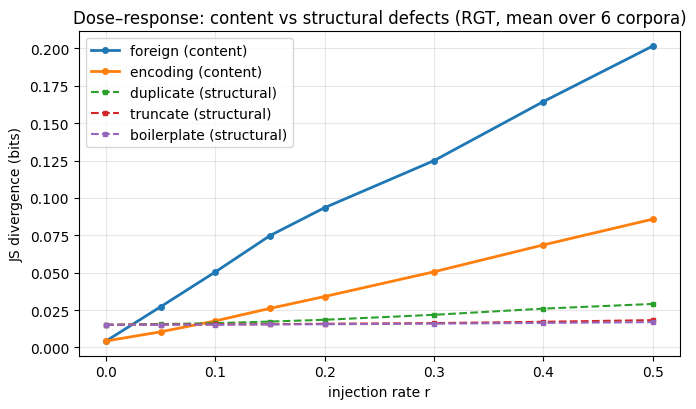

In [ ]:
import matplotlib.pyplot as plt
R = [str(r) for r in RATES]; X = RATES
CONTENT = ["foreign", "encoding"]
STRUCT  = ["duplicate", "truncate", "boilerplate"]

fig, ax = plt.subplots(figsize=(7, 4.2))
for d in CONTENT:
    m = [st.mean([st.mean(results[d][c][r]["rgt"]) for c in CORPORA]) for r in R]
    ax.plot(X, m, marker="o", ms=4, lw=2, label=f"{d} (content)")
for d in STRUCT:
    m = [st.mean([st.mean(results[d][c][r]["rgt"]) for c in CORPORA]) for r in R]
    ax.plot(X, m, marker="s", ms=3, lw=1.5, ls="--", label=f"{d} (structural)")
ax.set_xlabel("injection rate r"); ax.set_ylabel("JS divergence (bits)")
ax.set_title("Dose–response: content vs structural defects (RGT, mean over 6 corpora)")
ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

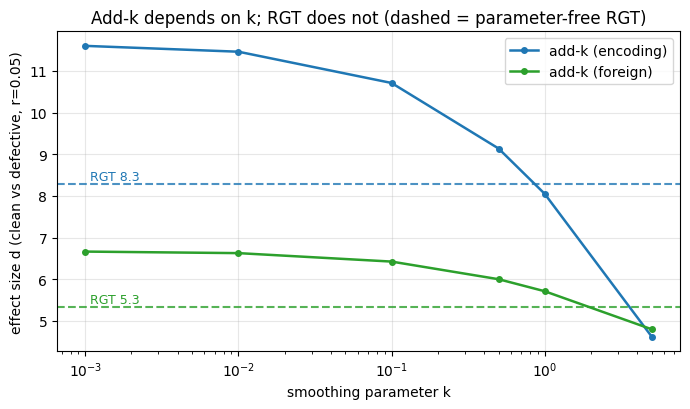

In [ ]:
# Smoothing: add-k depends on k; RGT (parameter-free) matches its strong end.
import json
sw = json.load(open("smoothing_sweep_six.json"))

fig, ax = plt.subplots(figsize=(7, 4.2))
colors = {"encoding": "tab:blue", "foreign": "tab:green"}
for defect in ["encoding", "foreign"]:
    ks = sw[defect]["ks"]
    ax.semilogx(ks, sw[defect]["addk_d"], marker="o", ms=4, lw=1.8,
                color=colors[defect], label=f"add-k ({defect})")
    ax.axhline(sw[defect]["rgt_d"], ls="--", lw=1.5, color=colors[defect], alpha=0.8)
    ax.annotate(f"RGT {sw[defect]['rgt_d']:.1f}", xy=(ks[0], sw[defect]["rgt_d"]),
                xytext=(3, 3), textcoords="offset points", fontsize=9, color=colors[defect])
ax.set_xlabel("smoothing parameter k"); ax.set_ylabel("effect size d (clean vs defective, r=0.05)")
ax.set_title("Add-k depends on k; RGT does not (dashed = parameter-free RGT)")
ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

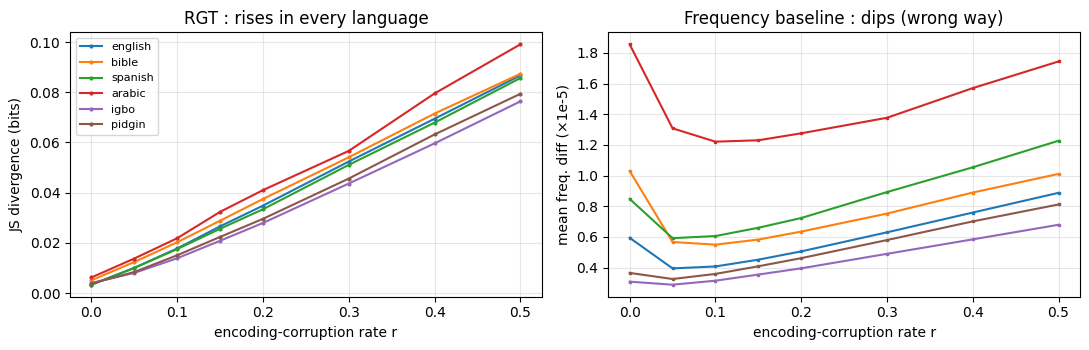

In [ ]:
# RGT rises, baseline dips in every language
fig, ax = plt.subplots(1, 2, figsize=(11,3.6))
for c in CORPORA:
    ax[0].plot(X, [st.mean(results["encoding"][c][r]["rgt"]) for r in R], marker="o", ms=2, label=c)
    ax[1].plot(X, [st.mean(results["encoding"][c][r]["baseline"])*1e5 for r in R], marker="s", ms=2, label=c)
ax[0].set_title("RGT : rises in every language"); ax[1].set_title("Frequency baseline : dips (wrong way)")
for a in ax: a.set_xlabel("encoding-corruption rate r"); a.grid(alpha=.3)
ax[0].set_ylabel("JS divergence (bits)"); ax[1].set_ylabel("mean freq. diff (×1e-5)")
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

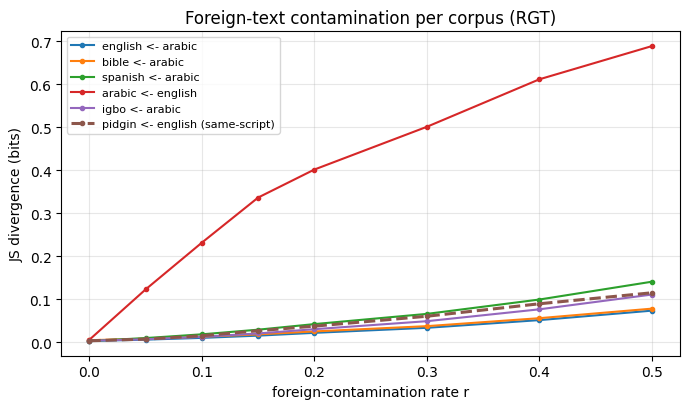

In [25]:
# Foreign contamination, per corpus (RGT). Pidgin<-English is the same-script hard case.
fig, ax = plt.subplots(figsize=(7, 4.2))
for c in CORPORA:
    same_script = (c == "pidgin")
    partner = FOREIGN_PARTNER[c]
    ax.plot(X, [st.mean(results["foreign"][c][r]["rgt"]) for r in R],
            marker="o", ms=3, lw=(2.2 if same_script else 1.5),
            ls=("--" if same_script else "-"),
            label=f"{c} <- {partner}" + (" (same-script)" if same_script else ""))
ax.set_xlabel("foreign-contamination rate r"); ax.set_ylabel("JS divergence (bits)")
ax.set_title("Foreign-text contamination per corpus (RGT)")
ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

---
## Summary

- **Principle:** defects leave evidence between documents (structural) or in the
  aggregate (content).
- **Prediction:** evidence location dictates the measurement level hence falsifiable.
- **Instrument:** RGT gives a parameter-free corpus-level measure; controlled
  injection supplies ground truth.
- **Result:** across five languages and two scripts, content defects are detected
  strongly at the corpus level (mean d = 8.3, 5.3) while the standard baseline
  fails with the wrong sign; structural defects reach document-level ROC-AUC =
  1.000. The framework's prediction holds language-independently.

**Limitation / future work:** the substrate spans Latin and Arabic scripts but
only *space-delimited* writing systems; scripts requiring segmentation (Chinese,
Japanese, Thai) are the next frontier.